# Task 4: Netflix Content Segmentation
Group Netflix titles into meaningful clusters using K-Means (unsupervised machine learning).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

## Load the Dataset

In [2]:
df = pd.read_csv("Dataset.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Step 1: Prepare numerical and categorical features

### Check for hidden missing values

In [3]:
# Missing values are written as the text "Not Given" in this dataset, so pandas does not count them as empty cells
print((df == "Not Given").sum())

show_id            0
type               0
title              0
director        2588
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
dtype: int64


### Numerical features (duration and release year)

In [4]:
# Movies have minutes, TV shows have seasons, so split them into two columns
df["is_movie"] = (df["type"] == "Movie").astype(int)

duration_number = df["duration"].str.extract(r"(\d+)")[0].astype(int)
df["duration_min"] = np.where(df["is_movie"] == 1, duration_number, 0)
df["seasons"] = np.where(df["is_movie"] == 0, duration_number, 0)

df[["type", "duration", "duration_min", "seasons"]].head()

,type,duration,duration_min,seasons
0,Movie,90 min,90,0
1,TV Show,1 Season,0,1
2,TV Show,1 Season,0,1
3,Movie,91 min,91,0
4,Movie,125 min,125,0


### Group the ratings

In [5]:
# 14 ratings are too many, so put them into 5 age groups
def rating_group(r):
    if r in ["TV-Y", "TV-Y7", "TV-Y7-FV", "G", "TV-G"]:
        return "Kids"
    elif r in ["PG", "TV-PG"]:
        return "Family"
    elif r in ["PG-13", "TV-14"]:
        return "Teen"
    elif r in ["R", "TV-MA", "NC-17"]:
        return "Adult"
    else:
        return "Unrated"

df["rating_group"] = df["rating"].apply(rating_group)
df["rating_group"].value_counts()

rating_group
Adult      4007
Teen       2647
Family     1148
Kids        906
Unrated      82
Name: count, dtype: int64

### Genres (top 12)

In [6]:
# Each title can have several genres, so make one 0/1 column for each top genre
all_genres = df["listed_in"].str.split(", ").explode()
top_genres = list(all_genres.value_counts().head(12).index)

for g in top_genres:
    df["genre_" + g] = df["listed_in"].apply(lambda s: int(g in s.split(", ")))

print(top_genres)

['International Movies', 'Dramas', 'Comedies', 'International TV Shows', 'Documentaries', 'Action & Adventure', 'TV Dramas', 'Independent Movies', 'Children & Family Movies', 'Romantic Movies', 'Thrillers', 'TV Comedies']


### Main country (top 5)

In [7]:
# Take the first country of each title, keep the top 5 and put the rest in "Other"
df["main_country"] = df["country"].str.split(",").str[0].str.strip()

top_countries = list(df.loc[df["main_country"] != "Not Given", "main_country"].value_counts().head(5).index)
df["country_group"] = df["main_country"].where(df["main_country"].isin(top_countries), "Other")

df["country_group"].value_counts()

country_group
United States     3240
Other             3163
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Name: count, dtype: int64

### Build the final feature table and scale it

In [8]:
# Scale the number columns to 0-1 so big numbers (like the year) do not dominate
number_cols = ["release_year", "duration_min", "seasons"]
scaled_numbers = pd.DataFrame(MinMaxScaler().fit_transform(df[number_cols]), columns=number_cols)

genre_cols = ["genre_" + g for g in top_genres]
rating_dummies = pd.get_dummies(df["rating_group"], prefix="rating").astype(int)
country_dummies = pd.get_dummies(df["country_group"], prefix="country").astype(int)

X = pd.concat([scaled_numbers, df[["is_movie"] + genre_cols], rating_dummies, country_dummies], axis=1)

print("Feature table shape:", X.shape)
X.head()

Feature table shape: (8790, 27)


,release_year,duration_min,seasons,is_movie,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,...,rating_Family,rating_Kids,rating_Teen,rating_Unrated,country_Canada,country_India,country_Other,country_Pakistan,country_United Kingdom,country_United States
0,0.989583,0.288462,0.000000,1,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
1,1.000000,0.000000,0.058824,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
2,1.000000,0.000000,0.058824,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1.000000,0.291667,0.000000,1,0,0,1,0,0,0,...,1,0,0,0,0,0,1,0,0,0
4,0.708333,0.400641,0.000000,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


## Step 2: Apply clustering algorithms

### Find a good number of clusters (k)

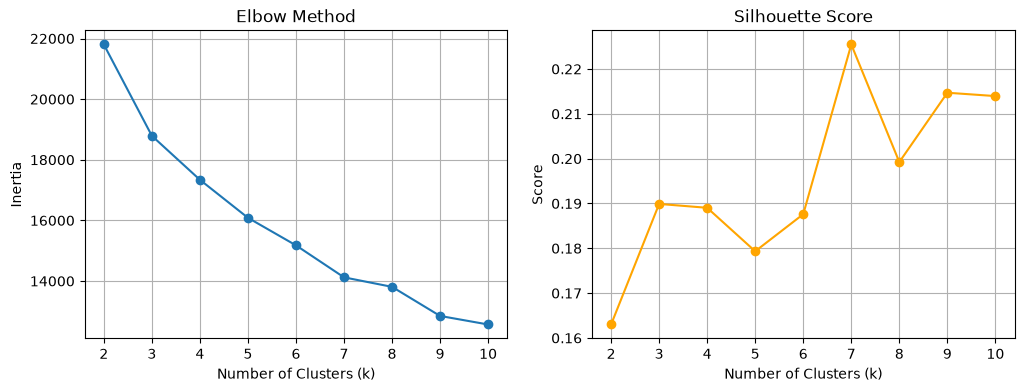

In [9]:
# Try k from 2 to 10 and note the error (inertia) and the silhouette score
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(list(k_values), silhouettes, marker="o", color="orange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Score")
axes[1].grid(True)

plt.show()

### Train K-Means

In [10]:
# k = 7 has the highest silhouette score
k = 7

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X)

print("Silhouette score:", round(silhouette_score(X, df["cluster"], sample_size=3000, random_state=42), 3))

Silhouette score: 0.225


## Step 3: Identify content groups

cluster
0     965
1     848
2    1813
3    1046
4    1975
5    1409
6     734
Name: count, dtype: int64


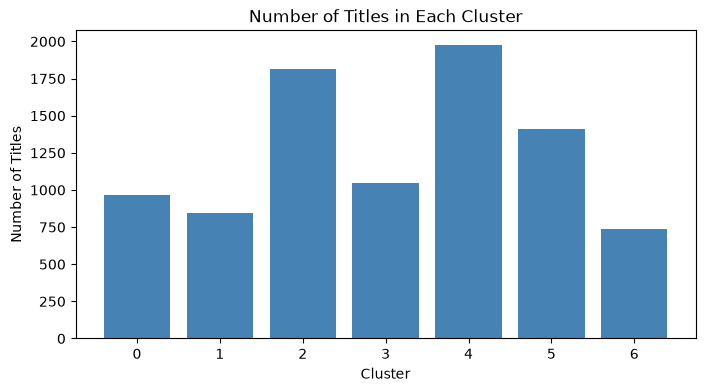

In [11]:
cluster_sizes = df["cluster"].value_counts().sort_index()
print(cluster_sizes)

plt.figure(figsize=(8, 4))
plt.bar(cluster_sizes.index.astype(str), cluster_sizes.values, color="steelblue")
plt.title("Number of Titles in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Titles")
plt.show()

## Step 4: Visualize clusters

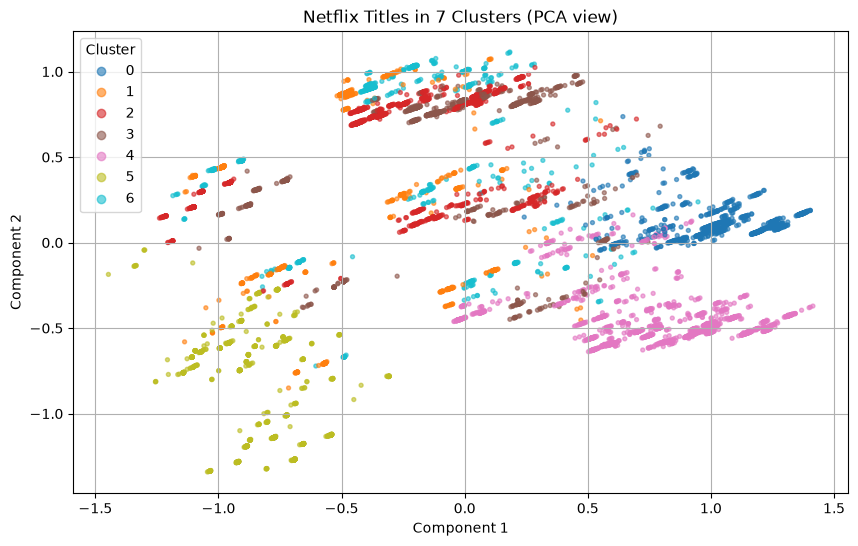

In [12]:
# Squeeze all the features into 2 dimensions so we can draw them
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(points[:, 0], points[:, 1], c=df["cluster"], cmap="tab10", s=8, alpha=0.6)
plt.title("Netflix Titles in 7 Clusters (PCA view)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True)
plt.show()

### Genre share in each cluster

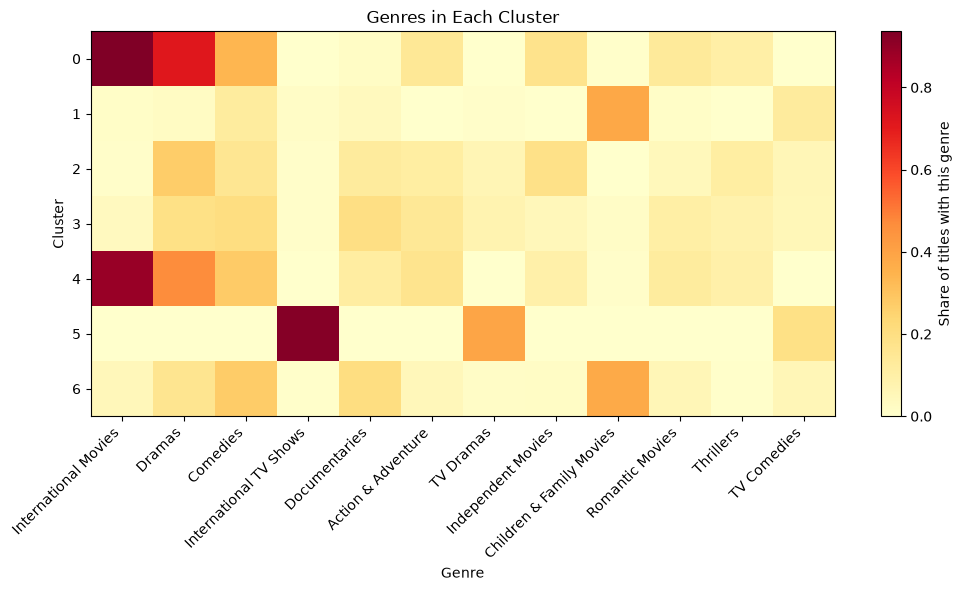

In [13]:
genre_by_cluster = df.groupby("cluster")[genre_cols].mean()
genre_by_cluster.columns = [c.replace("genre_", "") for c in genre_by_cluster.columns]

plt.figure(figsize=(12, 5))
plt.imshow(genre_by_cluster.values, cmap="YlOrRd", aspect="auto")
plt.colorbar(label="Share of titles with this genre")
plt.xticks(range(len(genre_by_cluster.columns)), genre_by_cluster.columns, rotation=45, ha="right")
plt.yticks(range(len(genre_by_cluster.index)), genre_by_cluster.index)
plt.title("Genres in Each Cluster")
plt.xlabel("Genre")
plt.ylabel("Cluster")
plt.show()

## Step 5: Interpret cluster characteristics

In [14]:
profile_rows = []

for c in sorted(df["cluster"].unique()):
    part = df[df["cluster"] == c]
    movies = part[part["is_movie"] == 1]
    shows = part[part["is_movie"] == 0]
    main_genres = part[genre_cols].mean().sort_values(ascending=False).head(3).index
    main_genres = ", ".join([g.replace("genre_", "") for g in main_genres])

    profile_rows.append({
        "Cluster": c,
        "Titles": len(part),
        "% Movies": round(part["is_movie"].mean() * 100),
        "Avg Release Year": round(part["release_year"].mean()),
        "Avg Movie Length (min)": round(movies["duration_min"].mean()) if len(movies) > 0 else None,
        "Avg Seasons": round(shows["seasons"].mean(), 1) if len(shows) > 0 else None,
        "Top Rating Group": part["rating_group"].value_counts().idxmax(),
        "Top Country": part["country_group"].value_counts().idxmax(),
        "Top Genres": main_genres
    })

profile = pd.DataFrame(profile_rows)
profile

,Cluster,Titles,% Movies,Avg Release Year,Avg Movie Length (min),Avg Seasons,Top Rating Group,Top Country,Top Genres
0,0,965,100,2012,127.0,NaN,Teen,India,"International Movies, Dramas, Comedies"
1,1,848,47,2015,65.0,1.9,Kids,United States,"Children & Family Movies, TV Comedies, Comedies"
2,2,1813,80,2014,94.0,2.0,Adult,United States,"Dramas, Independent Movies, Comedies"
3,3,1046,76,2012,97.0,2.7,Teen,United States,"Comedies, Documentaries, Dramas"
4,4,1975,100,2015,102.0,NaN,Adult,Other,"International Movies, Dramas, Comedies"
5,5,1409,0,2017,NaN,1.4,Adult,Other,"International TV Shows, TV Dramas, TV Comedies"
6,6,734,74,2012,88.0,1.9,Family,United States,"Children & Family Movies, Comedies, Documentaries"


# Conclusion

## What I did
I used K-Means to group 8,790 Netflix titles into clusters. The features were the type (Movie or TV Show), release year, duration (minutes for movies, seasons for TV shows), age rating group, the 12 most common genres and the main country. I scaled the number columns so that big numbers did not dominate the small ones.

## Choosing the number of clusters
I tried 2 to 10 clusters. The elbow graph had no sharp bend, so it did not give a clear answer. The silhouette score was highest at **k = 7** (about 0.22), so I chose 7 clusters. The score is still low, which is normal for data made of many 0/1 columns.

## The 7 groups I found

| Cluster | Group name | Titles | What it looks like |
|---|---|---|---|
| 0 | Indian movies | 965 | All movies, the longest (about 127 minutes), international dramas and comedies, rated for teens |
| 1 | Kids content | 848 | About half movies and half TV shows, short (about 65 minutes), kids rating, children and family genres |
| 2 | US adult dramas and comedies | 1,813 | Mostly movies (80%), about 94 minutes, dramas, independent films and comedies, mostly adult rated |
| 3 | US comedies and documentaries | 1,046 | A mix of movies (76%) and TV shows, comedies, documentaries and dramas, almost all rated for teens |
| 4 | International movies | 1,975 | All movies, about 102 minutes, from countries other than the US and India, mostly adult rated |
| 5 | International TV shows | 1,409 | All TV shows, newest group (average year 2017), about 1.4 seasons, mostly adult rated |
| 6 | Family movies | 734 | Mostly movies (74%), about 88 minutes, family rating, children and family films and comedies |

## What I learned
- Cluster 5 (international TV shows) holds just over half (53%) of all TV shows. Cluster 1 (kids) is also a little more than half TV shows, and all the other groups are mostly or fully movies.
- Country and genre made the movie groups different from each other, for example Indian movies, US movies and other international movies.
- Kids and family content was split into two groups: clusters 1 and 6. Cluster 1 has the kids rating and more TV shows, and cluster 6 has the family rating and more movies.
- The newest content is the international TV shows group (average year 2017), and the oldest is the Indian movies group (average year about 2012).

## Limitations
- The silhouette score is low (about 0.22), so the groups overlap and the borders between them are not sharp.
- Clusters 2 and 3 are mixed groups with both movies and TV shows, so they are harder to describe.
- I only used the top 12 genres and top 5 countries, so smaller genres and countries are not shown clearly.
- The director column was not used because 29% of its values are not given.
- K-Means needs me to choose k, and a different k would give different groups.

## Future improvement
I can try other methods like Hierarchical Clustering or DBSCAN, use more genres and countries, and compare the results with K-Means.